# Task 1: Iris Flower Classification

## Datheon Machine Learning & Data Science Internship

### Objective
The objective of this project is to build and compare
two supervised classification models using the Iris dataset.

### Models
1. Logistic Regression
2. Decision Tree Classifier

### Workflow
- Load and explore the dataset
- Perform exploratory data analysis
- Split the data into training and testing sets
- Apply feature scaling
- Train both classification models
- Evaluate accuracy, precision, recall and F1-score
- Visualize confusion matrices and decision boundaries

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

sns.set_theme(style="whitegrid")

In [33]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [34]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

display(df.describe())

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


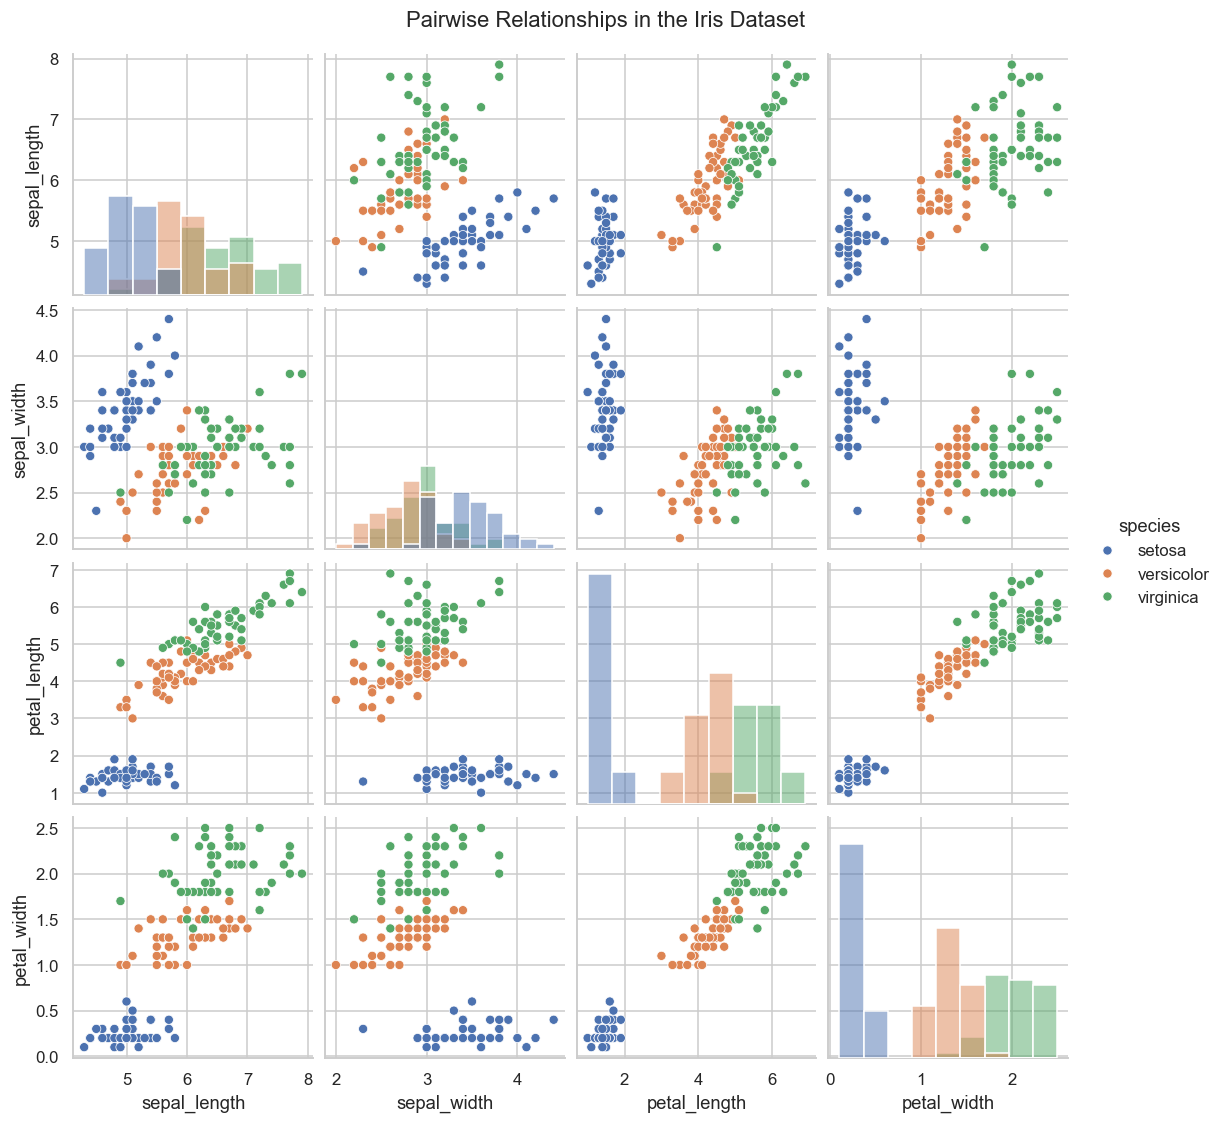

In [35]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairwise Relationships in the Iris Dataset", y=1.02)
plt.show()

In [36]:
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [37]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.


In [38]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [39]:
for name, y_pred in predictions.items():
    print(f"\n{name}")
    print("-" * 50)
    print(classification_report(y_test, y_pred, zero_division=0))


Logistic Regression
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



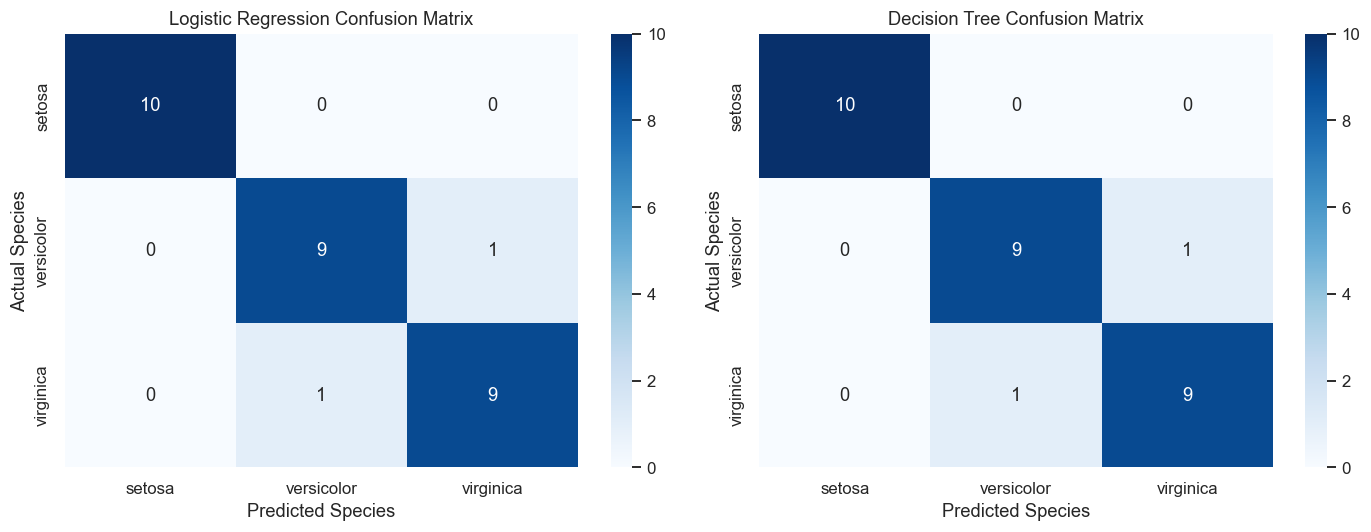

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=models[name].classes_)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=models[name].classes_,
        yticklabels=models[name].classes_,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

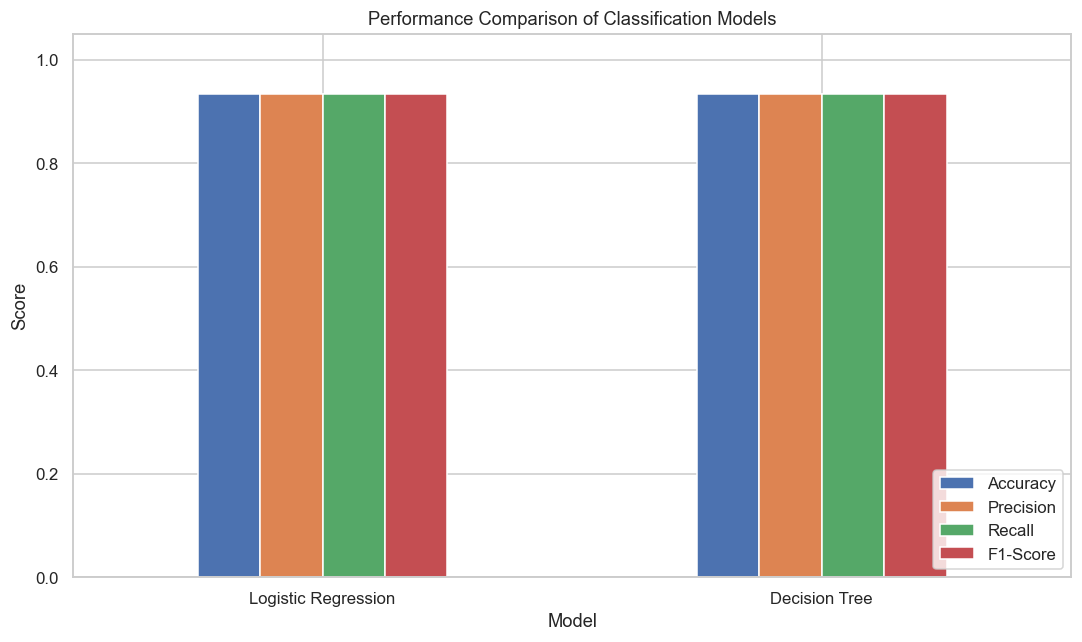

In [41]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

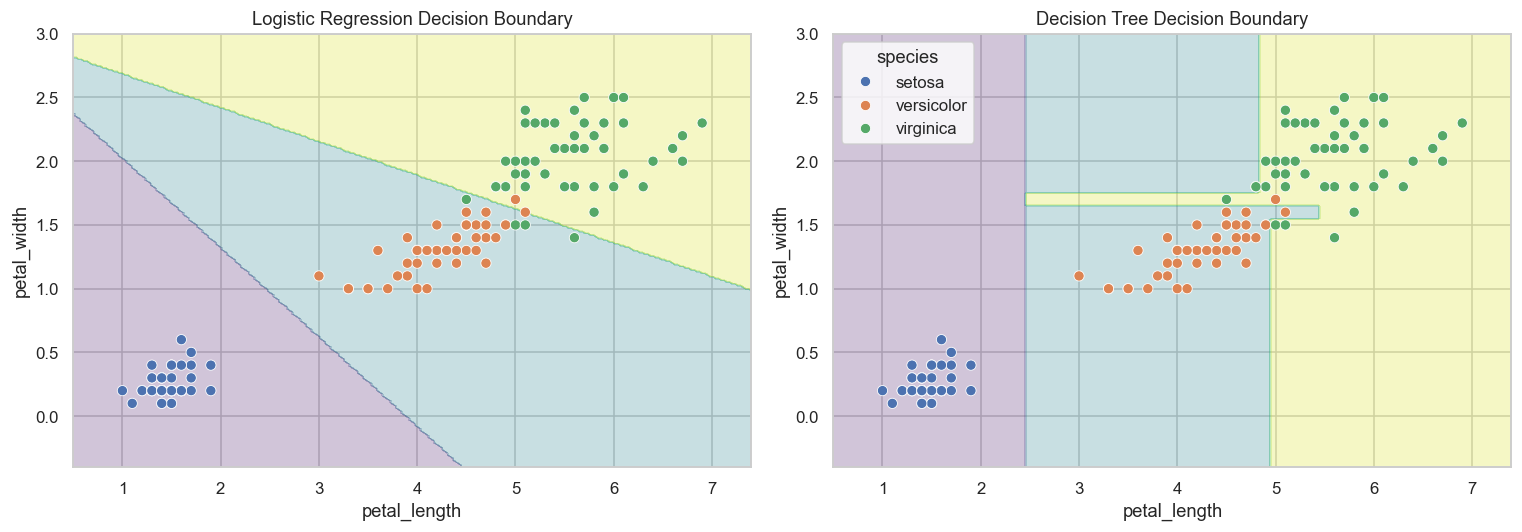

In [42]:
features = ["petal_length", "petal_width"]

X_two = df[features]
y_all = df["species"]

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_two,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models.items()):
    if name == "Logistic Regression":
        plot_model = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, random_state=42)
        )
    else:
        plot_model = DecisionTreeClassifier(random_state=42)

    plot_model.fit(X_train_2, y_train_2)

    x_min, x_max = X_two[features[0]].min() - 0.5, X_two[features[0]].max() + 0.5
    y_min, y_max = X_two[features[1]].min() - 0.5, X_two[features[1]].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame({
        features[0]: xx.ravel(),
        features[1]: yy.ravel()
    })

    Z = plot_model.predict(grid)

    # Convert predicted species into numeric values for plotting
    class_to_num = {
        species: i for i, species in enumerate(plot_model.classes_)
    }
    Z = np.array([class_to_num[label] for label in Z]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

    sns.scatterplot(
        data=df,
        x=features[0],
        y=features[1],
        hue="species",
        ax=ax,
        s=45,
        legend=(name == "Decision Tree")
    )

    ax.set_title(f"{name} Decision Boundary")

plt.tight_layout()
plt.show()

## Conclusion

Both Logistic Regression and Decision Tree were trained
and evaluated using the Iris dataset.

Their performance was compared using accuracy, precision,
recall, F1-score and confusion matrices.

The results show how different classification algorithms
separate flower species. The final preferred model should
be selected based on its evaluation metrics and
classification errors.